# Plan of Action

**Dataset: Human Activity Recognition with Samrtphone**

`Intro to Dataset:`
- Researchers selected 30 persons and tied smartphones on their waist.
- Then these people were asked to perform their day to day operations like walking, sleeping, sitting, laying, walking upstairs and downstarts etc...
- Using the sensors of the smartphones, all the readings along with the activity for that reading were recorded.
- There are 563 columns and around 7K rows and output column named `Activity`.
- We will reduce the columns from 563 to 100 
- We will train a `Logistic Regression`(Classification problem) model and see the accuracy before and after feature selection.
- We will notice that we got almost same accuracy for 100 columns.

- We will remove `Subject` column as it is a categorical column which indicates the person particular row belongs to.
- Here our data is scaled/normalized but scaling/normalization is required for `Variance Threshold method` only. Other methods doesn't require scaling/normalization.


# Note: 
- Always fill missing values before performing Feature Selection. `(Here, in our dataset, there are no misssing values)`
- Always perform feature selection on training data to avoide data leakage (We will learn what is data lekage in our upcoming sessions)
- Mostly, after feature selection, our accuracy will remain almost same or reduce but it will rarely increase bcz we are removing features.

In [41]:
import pandas as pd
import numpy as np

# Pandas
pd.set_option('display.float_format', '{:.15f}'.format)

# NumPy
np.set_printoptions(suppress=True, precision=15)

In [42]:
df = pd.read_csv(r"Human Activity Recognition\train.csv").drop(columns = ['subject'])

df.shape

(7352, 562)

In [43]:
 df.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity
0,0.288584510000000,-0.020294171000000,-0.132905140000000,-0.995278600000000,-0.983110610000000,-0.913526450000000,-0.995112080000000,-0.983184570000000,-0.923527020000000,-0.934723780000000,...,-0.298676370000000,-0.710304070000000,-0.112754340000000,0.030400372000000,-0.464761390000000,-0.018445884000000,-0.841246760000000,0.179940610000000,-0.058626924000000,STANDING
1,0.278418830000000,-0.016410568000000,-0.123520190000000,-0.998245280000000,-0.975300220000000,-0.960321990000000,-0.998807190000000,-0.974914370000000,-0.957686220000000,-0.943067510000000,...,-0.595050940000000,-0.861499310000000,0.053476955000000,-0.007434566100000,-0.732626210000000,0.703510590000000,-0.844787600000000,0.180288890000000,-0.054316717000000,STANDING
2,0.279653060000000,-0.019467156000000,-0.113461690000000,-0.995379560000000,-0.967187010000000,-0.978943960000000,-0.996519940000000,-0.963668370000000,-0.977468590000000,-0.938691550000000,...,-0.390748150000000,-0.760103720000000,-0.118559260000000,0.177899480000000,0.100699210000000,0.808529080000000,-0.848933470000000,0.180637310000000,-0.049117815000000,STANDING
3,0.279173940000000,-0.026200646000000,-0.123282570000000,-0.996091490000000,-0.983402700000000,-0.990675100000000,-0.997099470000000,-0.982749840000000,-0.989302500000000,-0.938691550000000,...,-0.117290200000000,-0.482844510000000,-0.036787973000000,-0.012892494000000,0.640011040000000,-0.485366450000000,-0.848649380000000,0.181934760000000,-0.047663183000000,STANDING
4,0.276628770000000,-0.016569655000000,-0.115361850000000,-0.998138620000000,-0.980817270000000,-0.990481630000000,-0.998321130000000,-0.979671870000000,-0.990441130000000,-0.942469120000000,...,-0.351470930000000,-0.699205150000000,0.123320050000000,0.122541960000000,0.693578290000000,-0.615970610000000,-0.847865250000000,0.185151160000000,-0.043892254000000,STANDING


In [44]:
df['Activity'].value_counts()

Activity
LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
Name: count, dtype: int64

In [45]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Splitting data into features and target_variable
x = df.drop(columns = 'Activity')
y = df['Activity']

# Encoding target variable 'Activity'
le = LabelEncoder()
y = le.fit_transform(y)

# Train test split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 1)

print(x_train.shape)
print(x_test.shape)

# Always perform feature selection on training data 
# to avoide data leakage (We will learn what is data lekage in our upcoming sessions)

(5881, 561)
(1471, 561)


# Applying Logistic Regression

In [46]:
lr = LogisticRegression()

# Fitting the data into the model
lr.fit(x_train, y_train)

# Makinng predictions on test data
y_pred = lr.predict(x_test)

# Finding accuracy
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy_1: {acc}")

Accuracy_1: 0.9864038069340585


c:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# Conclusion:
See, with 561 features(Columns), we are getting almost 0.98(98%) accuracy

# Next:
Now, we will remove 551 columns and keep only best performing 100 columns and see the accuracy.

- The very first step is to  remove duplicate columns.
- There're no any direct function available so we need to apply logic and find out.

In [7]:
import pandas as pd

df = pd.DataFrame({
    'A': [1, 2, 3],
    'B': [4, 5, 6],
    'C': [1, 2, 3],   # Same values as A
    'D': [4, 5, 6],   # Same values as B
    'E': [7, 8, 9]
})

# Find duplicates
print(df.columns[df.T.duplicated()].tolist())
# ['C', 'D']

# Remove duplicate columns
# df = df.loc[:, ~df.T.duplicated()]

# print(df)

['C', 'D']


In [8]:
def find_duplicates(df, remove = False):

    duplicate_cols = df.columns[df.T.duplicated()].tolist()
    print(duplicate_cols)

    if remove == True:
        if duplicate_cols:
            df = df.loc[:, ~df.T.duplicated()]
            print("Duplicate columns removed")
            return df
        else:
            print('No duplicate columns')
        

In [9]:
find_duplicates(x_train)

['tBodyAccMag-sma()', 'tGravityAccMag-mean()', 'tGravityAccMag-std()', 'tGravityAccMag-mad()', 'tGravityAccMag-max()', 'tGravityAccMag-min()', 'tGravityAccMag-sma()', 'tGravityAccMag-energy()', 'tGravityAccMag-iqr()', 'tGravityAccMag-entropy()', 'tGravityAccMag-arCoeff()1', 'tGravityAccMag-arCoeff()2', 'tGravityAccMag-arCoeff()3', 'tGravityAccMag-arCoeff()4', 'tBodyAccJerkMag-sma()', 'tBodyGyroMag-sma()', 'tBodyGyroJerkMag-sma()', 'fBodyAccMag-sma()', 'fBodyBodyAccJerkMag-sma()', 'fBodyBodyGyroMag-sma()', 'fBodyBodyGyroJerkMag-sma()']


In [10]:
x_train = find_duplicates(x_train, remove = True)
x_test = find_duplicates(x_test, remove = True)

print()
print(x_train.shape)
print(x_test.shape)

# Columns reduced from 561 to 540.
# Means there were 21 duplicate columns

['tBodyAccMag-sma()', 'tGravityAccMag-mean()', 'tGravityAccMag-std()', 'tGravityAccMag-mad()', 'tGravityAccMag-max()', 'tGravityAccMag-min()', 'tGravityAccMag-sma()', 'tGravityAccMag-energy()', 'tGravityAccMag-iqr()', 'tGravityAccMag-entropy()', 'tGravityAccMag-arCoeff()1', 'tGravityAccMag-arCoeff()2', 'tGravityAccMag-arCoeff()3', 'tGravityAccMag-arCoeff()4', 'tBodyAccJerkMag-sma()', 'tBodyGyroMag-sma()', 'tBodyGyroJerkMag-sma()', 'fBodyAccMag-sma()', 'fBodyBodyAccJerkMag-sma()', 'fBodyBodyGyroMag-sma()', 'fBodyBodyGyroJerkMag-sma()']
Duplicate columns removed
['tBodyAccMag-sma()', 'tGravityAccMag-mean()', 'tGravityAccMag-std()', 'tGravityAccMag-mad()', 'tGravityAccMag-max()', 'tGravityAccMag-min()', 'tGravityAccMag-sma()', 'tGravityAccMag-energy()', 'tGravityAccMag-iqr()', 'tGravityAccMag-entropy()', 'tGravityAccMag-arCoeff()1', 'tGravityAccMag-arCoeff()2', 'tGravityAccMag-arCoeff()3', 'tGravityAccMag-arCoeff()4', 'tBodyAccJerkMag-sma()', 'tBodyGyroMag-sma()', 'tBodyGyroJerkMag-sma()'

# Remove Duplicate Columns

In [47]:
# feature_engine library

from feature_engine.selection import DropDuplicateFeatures

dd  = DropDuplicateFeatures()

x_train = dd.fit_transform(x_train)
x_test = dd.transform(x_test)

print(x_train.shape, x_test.shape)


(5881, 540) (1471, 540)


In [48]:
# The transformer also stores the groups of duplicated features, which is useful for data analysis and validation.

dd.duplicated_feature_sets_

[{'tBodyAccMag-mean()',
  'tBodyAccMag-sma()',
  'tGravityAccMag-mean()',
  'tGravityAccMag-sma()'},
 {'tBodyAccMag-std()', 'tGravityAccMag-std()'},
 {'tBodyAccMag-mad()', 'tGravityAccMag-mad()'},
 {'tBodyAccMag-max()', 'tGravityAccMag-max()'},
 {'tBodyAccMag-min()', 'tGravityAccMag-min()'},
 {'tBodyAccMag-energy()', 'tGravityAccMag-energy()'},
 {'tBodyAccMag-iqr()', 'tGravityAccMag-iqr()'},
 {'tBodyAccMag-entropy()', 'tGravityAccMag-entropy()'},
 {'tBodyAccMag-arCoeff()1', 'tGravityAccMag-arCoeff()1'},
 {'tBodyAccMag-arCoeff()2', 'tGravityAccMag-arCoeff()2'},
 {'tBodyAccMag-arCoeff()3', 'tGravityAccMag-arCoeff()3'},
 {'tBodyAccMag-arCoeff()4', 'tGravityAccMag-arCoeff()4'},
 {'tBodyAccJerkMag-mean()', 'tBodyAccJerkMag-sma()'},
 {'tBodyGyroMag-mean()', 'tBodyGyroMag-sma()'},
 {'tBodyGyroJerkMag-mean()', 'tBodyGyroJerkMag-sma()'},
 {'fBodyAccMag-mean()', 'fBodyAccMag-sma()'},
 {'fBodyBodyAccJerkMag-mean()', 'fBodyBodyAccJerkMag-sma()'},
 {'fBodyBodyGyroMag-mean()', 'fBodyBodyGyroMag-sma(

# 1) Threshold Variance

**Note**: Always scale all the features first else a single variance threshold will not work for all the features.

- We may have two types of features.
    - `Constant features`: 
        - When in any feature, all values are same, such features are called **constant features**.
        - Such features have 0 variance
    - `Quasi Constant Features`:
        - Suppose there are 1000 rows. In column B, 990 rows has value `No`, only 10 rows has values `Yes`. Such features are called Quassi Constant Features.
        - Such features have variance very near to 0.

As such features have very low variance (almost 0), they cannot help to differentiate target variable. So, we drop such features.

# Steps:
1) `Decide threshold`: This is to be decided based on domain knowledge. <br>
`In general, variance threshold is set between 0.01-0.1`
2) Find variance of all the features independently.
3) If feature_variance < threshold, drop that feature. 

In [49]:
from sklearn.feature_selection import VarianceThreshold

var_thres = VarianceThreshold(threshold = 0.05).set_output(transform= 'pandas')

var_thres.fit(x_train)

# .set_output() is now available in sklearn which returns pandas df inplace of numpy array.

,"threshold threshold: float, default=0Features with a training-set variance lower than this threshold willbe removed. The default is to keep all features with non-zero variance,i.e. remove the features that have the same value in all samples.",0.05


In [50]:
# To see which are the columns whose variance>threshold
# True means var>thres and False means var<thres

print(var_thres.get_support())
print()
print(sum(var_thres.get_support()))    # Shows no of columns whose var>threshold

[False False False  True  True  True  True  True  True  True  True  True
  True  True  True  True  True False False  True  True  True  True  True
  True  True  True  True  True  True False False False  True False  True
  True  True  True  True  True  True  True False False False False False
 False  True  True  True  True  True  True  True  True  True  True False
 False False  True  True  True False False False False  True  True  True
  True  True  True  True  True  True  True  True False False False  True
  True  True  True  True  True  True  True  True  True  True  True  True
 False  True False  True  True  True  True  True  True  True False  True
 False  True False  True False  True False  True  True  True  True  True
 False False False  True  True  True  True  True  True  True  True  True
  True False  True  True False False False  True  True  True  True  True
  True  True  True  True  True False False  True False  True  True  True
  True  True  True  True False False False  True  T

In [15]:
# See which are those columns

x_train.columns[var_thres.get_support()]

Index(['tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z',
       'tBodyAcc-mad()-X', 'tBodyAcc-mad()-Y', 'tBodyAcc-mad()-Z',
       'tBodyAcc-max()-X', 'tBodyAcc-max()-Y', 'tBodyAcc-max()-Z',
       'tBodyAcc-min()-X',
       ...
       'fBodyBodyGyroJerkMag-meanFreq()', 'fBodyBodyGyroJerkMag-skewness()',
       'fBodyBodyGyroJerkMag-kurtosis()', 'angle(tBodyAccMean,gravity)',
       'angle(tBodyAccJerkMean),gravityMean)',
       'angle(tBodyGyroMean,gravityMean)',
       'angle(tBodyGyroJerkMean,gravityMean)', 'angle(X,gravityMean)',
       'angle(Y,gravityMean)', 'angle(Z,gravityMean)'],
      dtype='object', length=352)

In [16]:
# Transform both x_train and x_test

x_train = var_thres.transform(x_train)
x_test = var_thres.transform(x_test)

print(x_train.shape)
print(x_test.shape)

# See, columns reduced from 540 to 352

(5881, 352)
(1471, 352)


In [17]:
x_train.head()

,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,tBodyAcc-max()-Y,tBodyAcc-max()-Z,tBodyAcc-min()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
496,-0.405515110000000,-0.173194960000000,-0.321126490000000,-0.487338650000000,-0.161211020000000,-0.226761510000000,-0.205266610000000,-0.215327720000000,-0.445081950000000,0.270150300000000,...,-0.068168369000000,-0.211781860000000,-0.575582930000000,-0.377919990000000,-0.559577330000000,0.928446760000000,-0.478931740000000,-0.617953430000000,0.347881910000000,0.102994770000000
268,-0.233301040000000,0.172564070000000,-0.212676480000000,-0.322970260000000,0.113081510000000,-0.174473470000000,-0.072014049000000,-0.045876316000000,-0.334417040000000,-0.332601060000000,...,0.241122180000000,-0.255036080000000,-0.615330490000000,-0.303534330000000,0.473156750000000,0.197129900000000,0.190555450000000,-0.689017490000000,0.297226510000000,0.099864376000000
2827,0.471572310000000,0.337680100000000,-0.343390420000000,0.424024920000000,0.102986270000000,-0.374544700000000,0.648501920000000,-0.014917094000000,-0.303666050000000,-0.331136110000000,...,-0.263288370000000,-0.121871500000000,-0.533421420000000,-0.825731160000000,0.748538870000000,0.935054960000000,-0.212998880000000,-0.846748370000000,0.202851850000000,0.000877797240000
4900,-0.989546890000000,-0.986400880000000,-0.960600770000000,-0.989921860000000,-0.985914800000000,-0.956990900000000,-0.932950170000000,-0.568009980000000,-0.799147560000000,0.842901090000000,...,0.271096920000000,-0.351013630000000,-0.726152970000000,-0.069747826000000,-0.033054007000000,0.254039240000000,0.602662770000000,-0.561772470000000,0.206631410000000,0.310255980000000
3321,-0.994308270000000,-0.991059160000000,-0.989503120000000,-0.995415510000000,-0.992298160000000,-0.990105820000000,-0.940441510000000,-0.543612530000000,-0.831189020000000,0.839826540000000,...,0.315559970000000,-0.175210810000000,-0.534730900000000,-0.027036741000000,0.128738350000000,-0.354465050000000,-0.222856370000000,0.397896700000000,-0.303658240000000,-0.682670930000000


In [52]:
result = pd.DataFrame({
    'variance': x_train.var(),
    'selected': var_thres.get_support()
})

result

,variance,selected
tBodyAcc-mean()-X,0.005155372319526,False
tBodyAcc-mean()-Y,0.001754013637232,False
tBodyAcc-mean()-Z,0.003404353706519,False
tBodyAcc-std()-X,0.202297513651033,True
tBodyAcc-std()-Y,0.254716538660640,True
...,...,...
"angle(tBodyGyroMean,gravityMean)",0.368781130494400,True
"angle(tBodyGyroJerkMean,gravityMean)",0.224324550186593,True
"angle(X,gravityMean)",0.262332795020598,True
"angle(Y,gravityMean)",0.088812222636688,True


# 2) Correlation

There are two approach in correlation based filtering.

    1) Between each feature.
        - Find correlation of all the columns with each other.
        - It returns a value between -1 and 1.
        - (-1) means strong negative correlation and 1 means strong positive correlation
        - We decide a threshold, say 0.95, if corr between features is >0.95 or <(-0.95), we will drop any one feature from them.
        - We mostly use this approach

    2) Between a feature and target variable.
        - Finds correlation of each feature with the target variable.
        - We then decide a cut off, say 0.3 and -0.3.
        - We keep those features where corr>0.3 and corr<-0.3 (Corr between the feature and target variable)




In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

In [19]:
correlation = x_train.corr().abs()
correlation

# Using abs() so that we can later drop all corr>0.95 and corr<-0.95

,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,tBodyAcc-max()-Y,tBodyAcc-max()-Z,tBodyAcc-min()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
tBodyAcc-std()-X,1.000000000000000,0.926584249683477,0.851103060172216,0.998629498744691,0.919944864571552,0.846069413766672,0.980685440603741,0.891469286929487,0.844747213186943,0.965771946817284,...,0.065759274657326,0.152599732773048,0.118790951831815,0.042098647140578,0.015511689020767,0.029301828754222,0.021913656645880,0.370054254983958,0.470776480921702,0.401278429549614
tBodyAcc-std()-Y,0.926584249683477,1.000000000000000,0.894777650962584,0.922210848089371,0.997352570226305,0.893946822498042,0.915861853696053,0.952970203288455,0.882910078845633,0.936633914173458,...,0.103396121500409,0.212138234875466,0.182181642768887,0.028149232027394,0.006384655697167,0.002609738780351,0.010185140146973,0.377727604692275,0.521271672388896,0.439911373713638
tBodyAcc-std()-Z,0.851103060172216,0.894777650962584,1.000000000000000,0.844081513159807,0.891106592087847,0.997420820447421,0.853293201144700,0.863699329608342,0.939092228405085,0.859486570802730,...,0.093303786602953,0.162842060765351,0.131610865821812,0.016479071039523,0.010278963212358,0.011008435841284,0.002522713686078,0.340713612287263,0.472344410782494,0.490204590955459
tBodyAcc-mad()-X,0.998629498744691,0.922210848089371,0.844081513159807,1.000000000000000,0.915511342131208,0.839169763738882,0.973058826763573,0.886504639480896,0.838685488847191,0.961525028316405,...,0.059590833463294,0.153498678863917,0.120756795759159,0.051134575547355,0.014999016252511,0.029603864596403,0.021733005755491,0.366591412246146,0.466330369425950,0.397402711150855
tBodyAcc-mad()-Y,0.919944864571552,0.997352570226305,0.891106592087847,0.915511342131208,1.000000000000000,0.890936567716302,0.908831582752457,0.948948564072885,0.878535327694457,0.931584929966735,...,0.100995308059055,0.206706408611386,0.178009307957146,0.031897003162142,0.005997887645322,0.001628155079573,0.007088505736081,0.374217898474328,0.522633729365921,0.438553883170379
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"angle(tBodyGyroMean,gravityMean)",0.029301828754222,0.002609738780351,0.011008435841284,0.029603864596403,0.001628155079573,0.015617132930149,0.035090028931272,0.003421139335644,0.021147788684773,0.011094311395760,...,0.027842151195329,0.032423821359665,0.021692114828892,0.006281863345161,0.007713349467107,1.000000000000000,0.113562850409582,0.013585142557250,0.000605109572582,0.016471019866006
"angle(tBodyGyroJerkMean,gravityMean)",0.021913656645880,0.010185140146973,0.002522713686078,0.021733005755491,0.007088505736081,0.002763667653196,0.025796977632973,0.004198642289240,0.003780294934915,0.014337712988442,...,0.003893316876384,0.005540981924145,0.002163093359752,0.023808173031646,0.038312940209199,0.113562850409582,1.000000000000000,0.024417708459416,0.011761215865488,0.005510055881035
"angle(X,gravityMean)",0.370054254983958,0.377727604692275,0.340713612287263,0.366591412246146,0.374217898474328,0.342952559882893,0.383420983485822,0.366534407083522,0.343237618758270,0.359179493382421,...,0.074011172095801,0.082410561834517,0.077179725205996,0.013404373259822,0.027406686496150,0.013585142557250,0.024417708459416,1.000000000000000,0.785052764431884,0.657221506302704
"angle(Y,gravityMean)",0.470776480921702,0.521271672388896,0.472344410782494,0.466330369425950,0.522633729365921,0.473507783175643,0.480856464569315,0.487434647374258,0.459976255347181,0.468366881122479,...,0.085020680722889,0.080542934044340,0.072013463516839,0.001002071575717,0.010484972943988,0.000605109572582,0.011761215865488,0.

In [20]:
from feature_engine.selection import DropCorrelatedFeatures

drop_corr_fetures = DropCorrelatedFeatures(threshold=0.95)

x_train = drop_corr_fetures.fit_transform(x_train)
x_test = drop_corr_fetures.transform(x_test)

x_train.head()
# Always use feature_engine as it is speciafically made for feature selection and is tested by data scientists.

,tBodyAcc-max()-Y,tBodyAcc-max()-Z,tBodyAcc-min()-X,tBodyAcc-min()-Y,tBodyAcc-entropy()-X,tBodyAcc-entropy()-Y,tBodyAcc-entropy()-Z,"tBodyAcc-arCoeff()-X,1","tBodyAcc-arCoeff()-X,2","tBodyAcc-arCoeff()-X,3",...,fBodyBodyGyroJerkMag-iqr(),fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
496,-0.215327720000000,-0.445081950000000,0.270150300000000,0.257359940000000,0.586738090000000,0.361274480000000,-0.103805950000000,-0.295105090000000,-0.004516150700000,0.266272350000000,...,-0.775619610000000,-0.068168369000000,-0.575582930000000,-0.377919990000000,-0.559577330000000,0.928446760000000,-0.478931740000000,-0.617953430000000,0.347881910000000,0.102994770000000
268,-0.045876316000000,-0.334417040000000,-0.332601060000000,-0.046427196000000,0.506997990000000,0.403932690000000,-0.059501205000000,-0.271205420000000,0.278141890000000,0.039108826000000,...,0.065337657000000,0.241122180000000,-0.615330490000000,-0.303534330000000,0.473156750000000,0.197129900000000,0.190555450000000,-0.689017490000000,0.297226510000000,0.099864376000000
2827,-0.014917094000000,-0.303666050000000,-0.331136110000000,-0.660783760000000,0.441657390000000,0.569684190000000,-0.071072053000000,-0.258844730000000,0.207146590000000,-0.365030720000000,...,-0.434164860000000,-0.263288370000000,-0.533421420000000,-0.825731160000000,0.748538870000000,0.935054960000000,-0.212998880000000,-0.846748370000000,0.202851850000000,0.000877797240000
4900,-0.568009980000000,-0.799147560000000,0.842901090000000,0.688357970000000,-0.416491340000000,-0.635367470000000,-0.351379890000000,0.012003269000000,-0.111291420000000,0.282671810000000,...,-0.988257350000000,0.271096920000000,-0.726152970000000,-0.069747826000000,-0.033054007000000,0.254039240000000,0.602662770000000,-0.561772470000000,0.206631410000000,0.310255980000000
3321,-0.543612530000000,-0.831189020000000,0.839826540000000,0.709215100000000,-0.780158750000000,-0.409424230000000,-0.933576160000000,-0.035525825000000,0.135511640000000,-0.126963120000000,...,-0.995275840000000,0.315559970000000,-0.534730900000000,-0.027036741000000,0.128738350000000,-0.354465050000000,-0.222856370000000,0.397896700000000,-0.303658240000000,-0.682670930000000


In [21]:
print(x_train.shape)
print(x_test.shape)

# See, no_of_columns reduced from 352 to 177

(5881, 177)
(1471, 177)


# 3) ANOVA

In [22]:
from sklearn.feature_selection import f_classif
from sklearn.feature_selection import SelectKBest


anova = SelectKBest(f_classif, k = 100).set_output(transform = 'pandas')

In [23]:
x_train = anova.fit_transform(x_train, y_train)
x_test = anova.transform(x_test)

In [24]:
# See the shape now

print(x_train.shape)
print(x_test.shape)

# See, no_of_columns reduced from 177 to 100

(5881, 100)
(1471, 100)


In [25]:
# See the selected columns

x_train.columns

# anova.get_feature_names_out()
# Both gives the same result

Index(['tBodyAcc-max()-Y', 'tBodyAcc-max()-Z', 'tBodyAcc-min()-X',
       'tBodyAcc-min()-Y', 'tBodyAcc-entropy()-X', 'tBodyAcc-entropy()-Y',
       'tBodyAcc-entropy()-Z', 'tBodyAcc-arCoeff()-X,1',
       'tBodyAcc-arCoeff()-X,2', 'tBodyAcc-arCoeff()-Y,1',
       'tBodyAcc-arCoeff()-Z,1', 'tBodyAcc-correlation()-X,Y',
       'tGravityAcc-energy()-Y', 'tGravityAcc-energy()-Z',
       'tGravityAcc-entropy()-X', 'tBodyAccJerk-max()-X',
       'tBodyAccJerk-max()-Y', 'tBodyAccJerk-max()-Z', 'tBodyAccJerk-min()-X',
       'tBodyAccJerk-min()-Y', 'tBodyAccJerk-min()-Z', 'tBodyGyro-max()-X',
       'tBodyGyro-max()-Z', 'tBodyGyro-min()-X', 'tBodyGyro-entropy()-X',
       'tBodyGyro-entropy()-Y', 'tBodyGyro-entropy()-Z',
       'tBodyGyro-arCoeff()-X,1', 'tBodyGyro-arCoeff()-X,2',
       'tBodyGyro-arCoeff()-Z,1', 'tBodyGyro-arCoeff()-Z,2',
       'tBodyGyro-arCoeff()-Z,3', 'tBodyGyroJerk-max()-X',
       'tBodyGyroJerk-max()-Y', 'tBodyGyroJerk-max()-Z',
       'tBodyGyroJerk-min()-X', 'tBody

# Work Till Now

We reduced no_of_columns from 561 to 100 using the following method


1. **Removed Duplicate Columns**
2. **Variance Threshold Method**
3. **Correlation Method** `(Removed columns having correlation >0.95 and <-0.95)`
4. **ANOVA Method**

- Initially we trained LogisticRegression model with 561 features and got 98% accuracy.
- Now, let's again train the LogisticRegression model with 100 features and see the accuracy.

In [26]:
# See the no_of features

print(x_train.shape)
print(x_test.shape)

(5881, 100)
(1471, 100)


In [27]:
lr = LogisticRegression(max_iter = 1000)
lr.fit(x_train, y_train)


y_pred = lr.predict(x_test)

acc = accuracy_score(y_test, y_pred)

print(f"Accuracy on 100 Features: {acc}")

# See, on 561 Columns, 98% accuracy and
# on 100 columns, 97% accuracy.
# Which is better? Obviously 97% on 100 columns.

Accuracy on 100 Features: 0.9714479945615228


# Chi Square

- Chi Square is applicable when we have both- feature and the target categorical.
- Here, our `Human Activity Recognization` dataset has all numeric features.
- So we will use Titanic dataset to learn Feature Selection using Chi Square

In [28]:
titanic = pd.read_csv(r"00_Titanic_Dataset.csv")  [["Survived", "Pclass", 'Sex', 'SibSp', 'Parch', 'Embarked']]
titanic.head()    # Survived is our target column

,Survived,Pclass,Sex,SibSp,Parch,Embarked
0,0,3,male,1,0,S
1,1,1,female,1,0,C
2,1,3,female,0,0,S
3,1,1,female,1,0,S
4,0,3,male,0,0,S


In [29]:
obs = pd.crosstab( titanic['Sex'], titanic['Survived'], margins = True)
obs

Survived,0,1,All
Sex,,,
female,81,385,466
male,734,109,843
All,815,494,1309


In [30]:
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import chi2
import matplotlib.pyplot as plt

In [31]:
# To use chi2 from sklearn.feature_selection, we need to encode categorical features first
le = LabelEncoder()

titanic_encoded = titanic.apply(le.fit_transform)

In [32]:
titanic_encoded

,Survived,Pclass,Sex,SibSp,Parch,Embarked
0,0,2,1,1,0,2
1,1,0,0,1,0,0
2,1,2,0,0,0,2
3,1,0,0,1,0,2
4,0,2,1,0,0,2
...,...,...,...,...,...,...
1304,0,2,1,0,0,2
1305,1,0,0,0,0,0
1306,0,2,1,0,0,2
1307,0,2,1,0,0,2


In [33]:
x = titanic_encoded.drop(columns = ['Survived'])
y = titanic_encoded.drop(columns = x.columns)

# Calculating chi2 statistics
chi_scores, p_values = chi2(x, y)

print(chi_scores)
print()
print(p_values)

[ 49.68637358199403  220.8162472989485     0.271022820192731
  29.938289779190782  10.218345713229867]

[0.000000000001804 0.                0.602646479770333 0.000000044601743
 0.001390505169721]


In [34]:
p_values = pd.Series(p_values, index = x.columns)
p_values.sort_values(inplace = True)
p_values

Sex        0.000000000000000
Pclass     0.000000000001804
Parch      0.000000044601743
Embarked   0.001390505169721
SibSp      0.602646479770333
dtype: float64

Text(0, 0.5, 'P_Values')

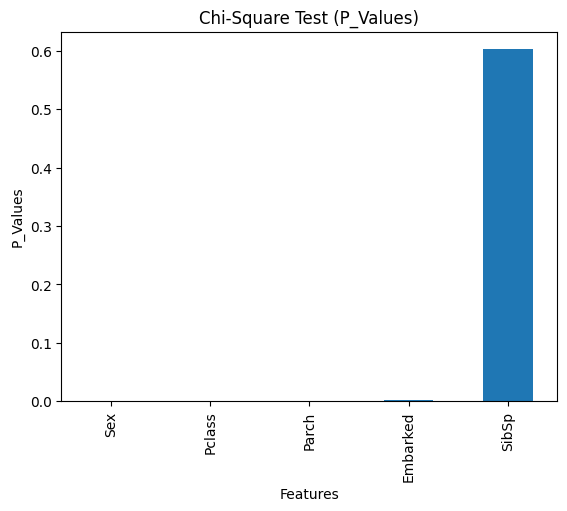

In [35]:
p_values.plot(kind = 'bar')

plt.title('Chi-Square Test (P_Values)')
plt.xlabel("Features")
plt.ylabel('P_Values')

# Chi2() with SelectKBest()

In [36]:
x_train, x_test, y_train, y_test = train_test_split(x, y,  test_size=0.2)
x_test

,Pclass,Sex,SibSp,Parch,Embarked
215,0,0,1,0,0
1129,1,0,1,1,2
385,1,1,0,0,2
620,2,1,1,0,0
1107,2,0,0,0,1
...,...,...,...,...,...
374,2,0,3,1,2
1044,2,0,0,2,2
1097,2,0,0,0,1
1258,2,0,0,0,2


In [37]:
selector = SelectKBest(score_func = chi2, k = 3).set_output(transform = 'pandas')
x_train_select = selector.fit_transform(x_train, y_train)
x_test_select = selector.transform(x_test)

In [38]:
x_train_select

,Pclass,Sex,Parch
184,2,0,2
621,0,1,0
1113,1,0,0
624,2,1,0
424,2,1,1
...,...,...,...
332,0,1,1
550,0,1,2
285,2,1,0
1050,2,0,2


In [39]:
x_test_select

,Pclass,Sex,Parch
215,0,0,0
1129,1,0,1
385,1,1,0
620,2,1,0
1107,2,0,0
...,...,...,...
374,2,0,1
1044,2,0,2
1097,2,0,0
1258,2,0,0


# Session Complete

# Next Session:
*Feature Selection Part 2: Wrapper Methods*